<a href="https://colab.research.google.com/github/DaviMillo/My-projects/blob/main/Previs%C3%A3oBlowOut_TCC_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Uso de Dados Sintéticos

# Bloco 1 — carregar e validar os dados


Adicionar Kick_Detection.csv e Formation_Pressure_Prediction.csv

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
from google.colab import files
from IPython.display import display

# Envie os arquivos CSV quando a janela do Colab aparecer.
uploaded = files.upload()

if not uploaded:
    raise FileNotFoundError("Nenhum arquivo foi enviado.")

def nome_sem_sufixo_colab(nome):
    """
    Normaliza nomes como:
    Kick_Detection (3).csv -> kick_detection.csv
    """
    caminho = Path(nome)
    nome_base = re.sub(r"\s*\(\d+\)$", "", caminho.stem)
    return f"{nome_base}{caminho.suffix}".lower()

def numero_sufixo_colab(nome):
    """Retorna o número entre parênteses acrescentado pelo Colab; sem sufixo = 0."""
    correspondencia = re.search(r"\((\d+)\)$", Path(nome).stem)
    return int(correspondencia.group(1)) if correspondencia else 0

def localizar_arquivo(nome_esperado):
    """
    Procura o arquivo enviado, aceitando sufixos automáticos do Colab.
    Se houver várias cópias renomeadas, escolhe a de maior sufixo.
    """
    esperado_normalizado = nome_sem_sufixo_colab(nome_esperado)
    nomes_enviados = list(uploaded.keys())

    # Primeiro, prefere o nome exato.
    exatos = [
        nome for nome in nomes_enviados
        if Path(nome).name.lower() == nome_esperado.lower()
    ]
    if exatos:
        escolhido = exatos[0]
        return Path("/content") / escolhido

    # Depois, aceita nomes como "Kick_Detection (3).csv".
    correspondentes = [
        nome for nome in nomes_enviados
        if nome_sem_sufixo_colab(nome) == esperado_normalizado
    ]

    if not correspondentes:
        lista = "\n".join(f"- {nome}" for nome in nomes_enviados)
        raise FileNotFoundError(
            f"Não encontrei {nome_esperado} entre os arquivos enviados.\n"
            f"Arquivos recebidos:\n{lista}"
        )

    escolhido = max(
        correspondentes,
        key=lambda nome: numero_sufixo_colab(nome)
    )
    print(f"Arquivo selecionado para {nome_esperado}: {escolhido}")
    return Path("/content") / escolhido

# Lê os arquivos, aceitando sufixos automáticos como "(3)".
kick_df = pd.read_csv(localizar_arquivo("Kick_Detection.csv"))
pressure_df = pd.read_csv(
    localizar_arquivo("Formation_Pressure_Prediction.csv")
)

# Converte colunas que parecem numéricas, preservando colunas textuais.
def converter_colunas_numericas(df):
    df = df.copy()

    for coluna in df.columns:
        if pd.api.types.is_numeric_dtype(df[coluna]):
            continue

        convertido = pd.to_numeric(df[coluna], errors="coerce")
        proporcao_numerica = convertido.notna().mean()

        # Só substitui a coluna se a maior parte dos valores for numérica.
        if proporcao_numerica >= 0.80:
            df[coluna] = convertido

    return df

kick_df = converter_colunas_numericas(kick_df)
pressure_df = converter_colunas_numericas(pressure_df)

# Valida as colunas necessárias para o benchmark.
colunas_alvo = {"FPress", "WBoPress"}
colunas_faltantes_kick = colunas_alvo - set(kick_df.columns)
colunas_faltantes_pressure = colunas_alvo - set(pressure_df.columns)

if colunas_faltantes_kick:
    raise ValueError(
        "Kick_Detection.csv não contém as colunas obrigatórias: "
        f"{sorted(colunas_faltantes_kick)}. "
        f"Colunas encontradas: {list(kick_df.columns)}"
    )

if colunas_faltantes_pressure:
    raise ValueError(
        "Formation_Pressure_Prediction.csv não contém as colunas obrigatórias: "
        f"{sorted(colunas_faltantes_pressure)}. "
        f"Colunas encontradas: {list(pressure_df.columns)}"
    )

if "ActiveGL" not in kick_df.columns:
    raise ValueError(
        "Kick_Detection.csv precisa ter a coluna ActiveGL "
        "para criar o rótulo proxy de kick."
    )

# Garante que os alvos e a coluna do rótulo proxy sejam numéricos.
for df_nome, df in [
    ("Kick_Detection", kick_df),
    ("Formation_Pressure_Prediction", pressure_df),
]:
    for coluna in ["FPress", "WBoPress"]:
        df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

kick_df["ActiveGL"] = pd.to_numeric(
    kick_df["ActiveGL"], errors="coerce"
)

# Verificações finais.
for nome, df in [
    ("Kick_Detection", kick_df),
    ("Formation_Pressure_Prediction", pressure_df),
]:
    if df.empty:
        raise ValueError(f"{nome}: o arquivo foi lido, mas está vazio.")

print("\nArquivos carregados:")
print(f"Kick_Detection: {kick_df.shape[0]} linhas × {kick_df.shape[1]} colunas")
print(
    "Formation_Pressure_Prediction: "
    f"{pressure_df.shape[0]} linhas × {pressure_df.shape[1]} colunas"
)

print("\nValores ausentes por coluna — Kick_Detection:")
display(kick_df.isna().sum().to_frame("n_ausentes").T)

print("\nValores ausentes por coluna — Formation_Pressure_Prediction:")
display(pressure_df.isna().sum().to_frame("n_ausentes").T)

print(
    "\nObservação: as divisões temporais seguintes usam a ordem das linhas "
    "dos CSVs. Confirme que essa ordem corresponde à sequência temporal "
    "ou operacional dos dados antes de interpretar os resultados como "
    "previsão futura."
)

Saving Formation_Pressure_Prediction.csv to Formation_Pressure_Prediction.csv
Saving Kick_Detection.csv to Kick_Detection.csv

Arquivos carregados:
Kick_Detection: 2337 linhas × 28 colunas
Formation_Pressure_Prediction: 2774 linhas × 28 colunas

Valores ausentes por coluna — Kick_Detection:


,CircFlow,FRate,FDensity,SMSpeed,BDepth,BSize,MVis,FPress,DPPress,CPress,...,WBoPress,BTBR,MPS1,MPS2,MPS3,AMTD,ATMPV,ATMYP,STP,WellDepth
n_ausentes,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Valores ausentes por coluna — Formation_Pressure_Prediction:


,CircFlow,FRate,FDensity,SMSpeed,BDepth,BSize,MVis,FPress,DPPress,CPress,...,WBoPress,BTBR,MPS1,MPS2,MPS3,AMTD,ATMPV,ATMYP,STP,WellDepth
n_ausentes,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Observação: as divisões temporais seguintes usam a ordem das linhas dos CSVs. Confirme que essa ordem corresponde à sequência temporal ou operacional dos dados antes de interpretar os resultados como previsão futura.


# Bloco 2 — configuração, modelos e funções de validação
#### A previsão de regressão será de um registro à frente. O modelo delta prevê a variação do alvo; a previsão final soma essa variação ao valor atual. Isso pressupõe que o valor atual do alvo esteja disponível no momento da previsão.



In [2]:
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.svm import SVR
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

SEED = 42

# Limite provisório para criar um rótulo proxy.
# Não equivale a um evento de kick confirmado.
KICK_PROXY_THRESHOLD = 1.0

TEST_FRACTIONS = [0.05, 0.10, 0.15]
TRAIN_WINDOWS = [None, 0.50]  # None = expansiva; 0.50 = móvel
N_SPLITS = 4
GAP = 1

# ATVolume foi observado como altamente correlacionado com ActiveGL.
# Excluí-lo do detector evita fornecer ao modelo um provável substituto
# direto da variável que define o rótulo proxy.
EXCLUDED_KICK_FEATURES = {"ActiveGL", "ATVolume"}

def temporal_splits(n, test_fraction, n_splits=4, gap=1,
                    train_window_fraction=None):
    """Folds walk-forward: cada treino contém apenas linhas anteriores ao teste."""
    test_size = max(2, int(np.ceil(n * test_fraction)))
    first_test_start = n - n_splits * test_size

    if first_test_start <= gap + 5:
        raise ValueError(
            f"Poucos registros: n={n}, test_fraction={test_fraction}, "
            f"n_splits={n_splits}, gap={gap}."
        )

    window_size = None
    if train_window_fraction is not None:
        window_size = max(10, int(n * train_window_fraction))

    splits = []
    for fold in range(n_splits):
        test_start = first_test_start + fold * test_size
        test_end = min(test_start + test_size, n)
        train_end = test_start - gap

        train_start = (
            0 if window_size is None
            else max(0, train_end - window_size)
        )

        train_idx = np.arange(train_start, train_end)
        test_idx = np.arange(test_start, test_end)

        if len(train_idx) > 0 and len(test_idx) > 0:
            splits.append((train_idx, test_idx))

    return splits

def metricas_regressao(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    validos = np.isfinite(y_real) & np.isfinite(y_pred)
    y_real = y_real[validos]
    y_pred = y_pred[validos]

    if len(y_real) == 0:
        return {"MAE": np.nan, "RMSE": np.nan, "vies": np.nan, "R2": np.nan}

    r2 = (
        r2_score(y_real, y_pred)
        if len(y_real) > 1 and np.var(y_real) > 1e-12
        else np.nan
    )

    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "vies": float(np.mean(y_pred - y_real)),
        "R2": r2,
    }

def construir_dados_regressao(df, alvo):
    """
    X no registro t prevê alvo em t+1.
    O modelo é treinado para prever delta = alvo(t+1) - alvo(t).
    """
    alvo_atual = pd.to_numeric(df[alvo], errors="coerce").reset_index(drop=True)

    # Exclui os alvos contemporâneos e ActiveGL das features gerais.
    # O alvo previsto entra somente como histórico explicitamente defasado.
    excluidas = {"FPress", "WBoPress", "ActiveGL"}
    features = [
        c for c in df.columns
        if c not in excluidas
        and pd.api.types.is_numeric_dtype(df[c])
    ]

    X = df[features].iloc[:-1].copy().reset_index(drop=True)
    X = X.replace([np.inf, -np.inf], np.nan)

    for lag in [0, 1, 2, 3]:
        X[f"{alvo}_lag{lag}"] = alvo_atual.shift(lag).iloc[:-1].to_numpy()

    y_futuro = alvo_atual.shift(-1).iloc[:-1].reset_index(drop=True)
    y_atual = alvo_atual.iloc[:-1].reset_index(drop=True)
    delta = y_futuro - y_atual

    valido = (
        np.isfinite(y_futuro.to_numpy())
        & np.isfinite(y_atual.to_numpy())
        & np.isfinite(delta.to_numpy())
    )

    return (
        X,
        y_futuro.astype(float),
        y_atual.astype(float),
        delta.astype(float),
        valido,
    )

def modelo_com_alvo_escalado(regressor):
    """Escala o alvo dentro do treino de cada fold; evita epsilon inadequado no SVR."""
    return TransformedTargetRegressor(
        regressor=regressor,
        transformer=StandardScaler()
    )

regression_models = {
    "Persistência": None,

    "Ridge_delta": modelo_com_alvo_escalado(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=10.0)),
        ])
    ),

    "ExtraTrees_delta": modelo_com_alvo_escalado(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", ExtraTreesRegressor(
                n_estimators=400,
                min_samples_leaf=2,
                random_state=SEED,
                n_jobs=-1,
            )),
        ])
    ),

    "GradientBoosting_delta": modelo_com_alvo_escalado(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.03,
                max_depth=2,
                min_samples_leaf=5,
                loss="huber",
                random_state=SEED,
            )),
        ])
    ),

    "HistGradientBoosting_delta": modelo_com_alvo_escalado(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", HistGradientBoostingRegressor(
                max_iter=200,
                learning_rate=0.04,
                max_leaf_nodes=15,
                l2_regularization=1.0,
                random_state=SEED,
            )),
        ])
    ),

    "RF_delta": modelo_com_alvo_escalado(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=250,
                min_samples_leaf=2,
                random_state=SEED,
                n_jobs=-1,
            )),
        ])
    ),

    "SVR_delta": modelo_com_alvo_escalado(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", SVR(C=10.0, epsilon=0.1, kernel="rbf")),
        ])
    ),
}

# Bloco 3 — benchmark de regressão
#### O resumo mantém separados o tamanho do teste e a janela de treino. Assim, não mistura configurações diferentes como se fossem folds independentes.



In [3]:
def executar_benchmark_regressao(datasets):
    resultados = []

    for nome_dataset, df in datasets.items():
        for alvo in ["FPress", "WBoPress"]:
            X, y_futuro, y_atual, delta, valido = construir_dados_regressao(
                df, alvo
            )

            for test_fraction in TEST_FRACTIONS:
                for train_window in TRAIN_WINDOWS:
                    splits = temporal_splits(
                        n=len(X),
                        test_fraction=test_fraction,
                        n_splits=N_SPLITS,
                        gap=GAP,
                        train_window_fraction=train_window,
                    )

                    for fold, (train_idx, test_idx) in enumerate(splits, 1):
                        train_ok = valido[train_idx]
                        test_ok = valido[test_idx]

                        train_idx_valid = train_idx[train_ok]
                        test_idx_valid = test_idx[test_ok]

                        if len(train_idx_valid) < 20 or len(test_idx_valid) == 0:
                            continue

                        y_train_delta = delta.iloc[train_idx_valid].to_numpy()
                        y_real = y_futuro.iloc[test_idx_valid].to_numpy()
                        baseline = y_atual.iloc[test_idx_valid].to_numpy()

                        config_janela = (
                            "expansiva" if train_window is None
                            else f"movel_{train_window:.0%}"
                        )

                        for nome_modelo, modelo in regression_models.items():
                            if modelo is None:
                                y_pred = baseline
                            else:
                                ajustado = clone(modelo)
                                ajustado.fit(
                                    X.iloc[train_idx_valid],
                                    y_train_delta
                                )
                                delta_pred = ajustado.predict(
                                    X.iloc[test_idx_valid]
                                )
                                y_pred = baseline + delta_pred

                            m = metricas_regressao(y_real, y_pred)

                            resultados.append({
                                "dataset": nome_dataset,
                                "alvo": alvo,
                                "modelo": nome_modelo,
                                "test_fraction": test_fraction,
                                "train_window": config_janela,
                                "fold": fold,
                                "n_train": len(train_idx_valid),
                                "n_test": len(test_idx_valid),
                                **m,
                            })

    return pd.DataFrame(resultados)

datasets = {
    "Kick_Detection": kick_df,
    "Formation_Pressure_Prediction": pressure_df,
}

reg_benchmark = executar_benchmark_regressao(datasets)

if reg_benchmark.empty:
    raise RuntimeError("O benchmark não gerou resultados; confira os dados.")

print("Métricas por configuração, alvo e modelo:")
reg_summary = (
    reg_benchmark
    .groupby(
        ["dataset", "alvo", "test_fraction", "train_window", "modelo"],
        as_index=False
    )
    .agg(
        MAE_medio=("MAE", "mean"),
        MAE_desvio=("MAE", "std"),
        RMSE_medio=("RMSE", "mean"),
        RMSE_desvio=("RMSE", "std"),
        vies_medio=("vies", "mean"),
        R2_medio=("R2", "mean"),
        n_folds=("fold", "count"),
    )
)
display(reg_summary.round(6))

# Comparação pareada com persistência, dentro da mesma configuração.
chaves = ["dataset", "alvo", "test_fraction", "train_window"]
base = (
    reg_summary[reg_summary["modelo"] == "Persistência"]
    [chaves + ["MAE_medio", "RMSE_medio"]]
    .rename(columns={
        "MAE_medio": "MAE_persistencia",
        "RMSE_medio": "RMSE_persistencia",
    })
)

comparacao = reg_summary.merge(base, on=chaves, how="left")
comparacao["melhoria_MAE_%"] = (
    100 * (comparacao["MAE_persistencia"] - comparacao["MAE_medio"])
    / comparacao["MAE_persistencia"]
)
comparacao["melhoria_RMSE_%"] = (
    100 * (comparacao["RMSE_persistencia"] - comparacao["RMSE_medio"])
    / comparacao["RMSE_persistencia"]
)

print("Melhoria percentual vs. persistência; positivo indica menor erro:")
display(
    comparacao[comparacao["modelo"] != "Persistência"][
        chaves + ["modelo", "melhoria_MAE_%", "melhoria_RMSE_%"]
    ].round(2)
)

Métricas por configuração, alvo e modelo:


,dataset,alvo,test_fraction,train_window,modelo,MAE_medio,MAE_desvio,RMSE_medio,RMSE_desvio,vies_medio,R2_medio,n_folds
0,Formation_Pressure_Prediction,FPress,0.05,expansiva,ExtraTrees_delta,5.969228,9.032037,7.563093,10.451896,-5.969004,-4.964568e+05,4
1,Formation_Pressure_Prediction,FPress,0.05,expansiva,GradientBoosting_delta,0.001160,0.001323,0.001204,0.001398,0.000767,9.896970e-01,4
2,Formation_Pressure_Prediction,FPress,0.05,expansiva,HistGradientBoosting_delta,18.586570,9.193597,20.343532,7.763956,-16.490237,-1.400772e+06,4
3,Formation_Pressure_Prediction,FPress,0.05,expansiva,Persistência,0.000471,0.000050,0.000688,0.000039,-0.000471,9.986850e-01,4
4,Formation_Pressure_Prediction,FPress,0.05,expansiva,RF_delta,69.225797,136.653784,69.250269,136.702696,-69.225497,-6.774861e+07,4
...,...,...,...,...,...,...,...,...,...,...,...,...
163,Kick_Detection,WBoPress,0.15,movel_50%,HistGradientBoosting_delta,0.318941,0.273310,0.472972,0.329998,0.105066,9.682230e-01,4
164,Kick_Detection,WBoPress,0.15,movel_50%,Persistência,0.347074,0.253095,0.461329,0.321442,0.194714,9.998160e-01,4
165,Kick_Detection,WBoPress,0.15,movel_50%,RF_delta,0.378963,0.496021,0.515669,0.539323,0.226246,9.997230e-01,4
166,Kick_Detection,WBoPress,0.15,movel_50%,Ridge_delta,3.045807,5.114034,3.852906,6.157097,2.478965,9.826310e-01,4


Melhoria percentual vs. persistência; positivo indica menor erro:


,dataset,alvo,test_fraction,train_window,modelo,melhoria_MAE_%,melhoria_RMSE_%
0,Formation_Pressure_Prediction,FPress,0.05,expansiva,ExtraTrees_delta,-1266652.23,-1098800.59
1,Formation_Pressure_Prediction,FPress,0.05,expansiva,GradientBoosting_delta,-146.23,-74.93
2,Formation_Pressure_Prediction,FPress,0.05,expansiva,HistGradientBoosting_delta,-3944225.48,-2955769.97
4,Formation_Pressure_Prediction,FPress,0.05,expansiva,RF_delta,-14690565.25,-10061810.07
5,Formation_Pressure_Prediction,FPress,0.05,expansiva,Ridge_delta,-1796376.47,-1255876.08
...,...,...,...,...,...,...,...
162,Kick_Detection,WBoPress,0.15,movel_50%,GradientBoosting_delta,26.32,17.99
163,Kick_Detection,WBoPress,0.15,movel_50%,HistGradientBoosting_delta,8.11,-2.52
165,Kick_Detection,WBoPress,0.15,movel_50%,RF_delta,-9.19,-11.78
166,Kick_Detection,WBoPress,0.15,movel_50%,Ridge_delta,-777.57,-735.17


#Bloco 4 — diagnóstico e avaliação do rótulo proxy de kick
#### O código só calcula métricas discriminativas em folds com as duas classes tanto no treino quanto no teste. Se nenhum fold atender a essa condição, não exibirá métricas como evidência de desempenho do detector.

In [4]:
classification_models = {
    "LogisticRegression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=SEED,
        )),
    ]),

    "RandomForestClassifier": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=250,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=SEED,
            n_jobs=-1,
        )),
    ]),

    "GradientBoostingClassifier": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=2,
            min_samples_leaf=5,
            random_state=SEED,
        )),
    ]),
}

def executar_diagnostico_kick(df):
    label = (
        pd.to_numeric(df["ActiveGL"], errors="coerce")
        > KICK_PROXY_THRESHOLD
    ).astype(int)

    # Prediz o rótulo proxy do próximo registro usando dados disponíveis agora.
    features = [
        c for c in df.columns
        if c not in EXCLUDED_KICK_FEATURES
        and pd.api.types.is_numeric_dtype(df[c])
    ]

    if not features:
        raise ValueError("Nenhuma feature numérica disponível para classificação.")

    X = df[features].iloc[:-1].copy().reset_index(drop=True)
    X = X.replace([np.inf, -np.inf], np.nan)
    y_next = label.shift(-1).iloc[:-1].reset_index(drop=True).astype(int)

    print(
        f"Rótulo proxy: {int(label.sum())} positivos em {len(label)} registros."
    )
    print("Features excluídas do detector:", sorted(EXCLUDED_KICK_FEATURES))

    registros = []

    for test_fraction in TEST_FRACTIONS:
        for train_window in TRAIN_WINDOWS:
            splits = temporal_splits(
                n=len(X),
                test_fraction=test_fraction,
                n_splits=N_SPLITS,
                gap=GAP,
                train_window_fraction=train_window,
            )

            for fold, (train_idx, test_idx) in enumerate(splits, 1):
                y_train = y_next.iloc[train_idx].to_numpy()
                y_test = y_next.iloc[test_idx].to_numpy()

                config_janela = (
                    "expansiva" if train_window is None
                    else f"movel_{train_window:.0%}"
                )

                train_both = len(np.unique(y_train)) == 2
                test_both = len(np.unique(y_test)) == 2

                base = {
                    "test_fraction": test_fraction,
                    "train_window": config_janela,
                    "fold": fold,
                    "positivos_treino": int(y_train.sum()),
                    "negativos_treino": int(len(y_train) - y_train.sum()),
                    "positivos_teste": int(y_test.sum()),
                    "negativos_teste": int(len(y_test) - y_test.sum()),
                    "fold_classificavel": bool(train_both and test_both),
                }

                for nome_modelo, modelo in classification_models.items():
                    linha = {**base, "modelo": nome_modelo}

                    if not train_both or not test_both:
                        linha.update({
                            "status": "não avaliável: falta uma classe",
                            "precisao": np.nan,
                            "recall": np.nan,
                            "F1": np.nan,
                            "AUROC": np.nan,
                            "average_precision": np.nan,
                        })
                        registros.append(linha)
                        continue

                    ajustado = clone(modelo)
                    ajustado.fit(X.iloc[train_idx], y_train)

                    y_pred = ajustado.predict(X.iloc[test_idx])
                    y_score = ajustado.predict_proba(X.iloc[test_idx])[:, 1]

                    linha.update({
                        "status": "avaliável",
                        "precisao": precision_score(
                            y_test, y_pred, zero_division=0
                        ),
                        "recall": recall_score(
                            y_test, y_pred, zero_division=0
                        ),
                        "F1": f1_score(
                            y_test, y_pred, zero_division=0
                        ),
                        "AUROC": roc_auc_score(y_test, y_score),
                        "average_precision": average_precision_score(
                            y_test, y_score
                        ),
                    })

                    tn, fp, fn, tp = confusion_matrix(
                        y_test, y_pred, labels=[0, 1]
                    ).ravel()
                    linha.update({
                        "TN": int(tn), "FP": int(fp),
                        "FN": int(fn), "TP": int(tp),
                    })
                    registros.append(linha)

    return pd.DataFrame(registros)

class_diagnostic = executar_diagnostico_kick(kick_df)

print("Distribuição de classes por fold:")
display(
    class_diagnostic[
        [
            "test_fraction", "train_window", "fold",
            "positivos_treino", "negativos_treino",
            "positivos_teste", "negativos_teste",
            "fold_classificavel",
        ]
    ].drop_duplicates().reset_index(drop=True)
)

n_validos = int(class_diagnostic["fold_classificavel"].sum())
print(f"Folds classificáveis por modelo: {n_validos}")

if n_validos == 0:
    print(
        "Nenhum fold contém as duas classes no treino e no teste. "
        "Não é possível avaliar validamente a discriminação de kick "
        "com esta sequência e esta divisão."
    )
else:
    display(
        class_diagnostic[class_diagnostic["status"] == "avaliável"]
        .groupby(
            ["test_fraction", "train_window", "modelo"],
            as_index=False
        )[["precisao", "recall", "F1", "AUROC", "average_precision"]]
        .mean()
        .round(4)
    )

Rótulo proxy: 810 positivos em 2337 registros.
Features excluídas do detector: ['ATVolume', 'ActiveGL']
Distribuição de classes por fold:


,test_fraction,train_window,fold,positivos_treino,negativos_treino,positivos_teste,negativos_teste,fold_classificavel
0,0.05,expansiva,1,341,1526,117,0,False
1,0.05,expansiva,2,458,1526,117,0,False
2,0.05,expansiva,3,575,1526,117,0,False
3,0.05,expansiva,4,692,1526,117,0,False
4,0.05,movel_50%,1,341,827,117,0,False
5,0.05,movel_50%,2,458,710,117,0,False
6,0.05,movel_50%,3,575,593,117,0,False
7,0.05,movel_50%,4,692,476,117,0,False
8,0.10,expansiva,1,0,1399,108,126,False
9,0.10,expansiva,2,107,1526,234,0,False


Folds classificáveis por modelo: 0
Nenhum fold contém as duas classes no treino e no teste. Não é possível avaliar validamente a discriminação de kick com esta sequência e esta divisão.


# Bloco 5 — gráficos, correlações e exportação dos resultados
#### O gráfico de regressão abaixo usa a configuração de teste de 15% com janela expansiva para não misturar configurações diferentes no mesmo painel.

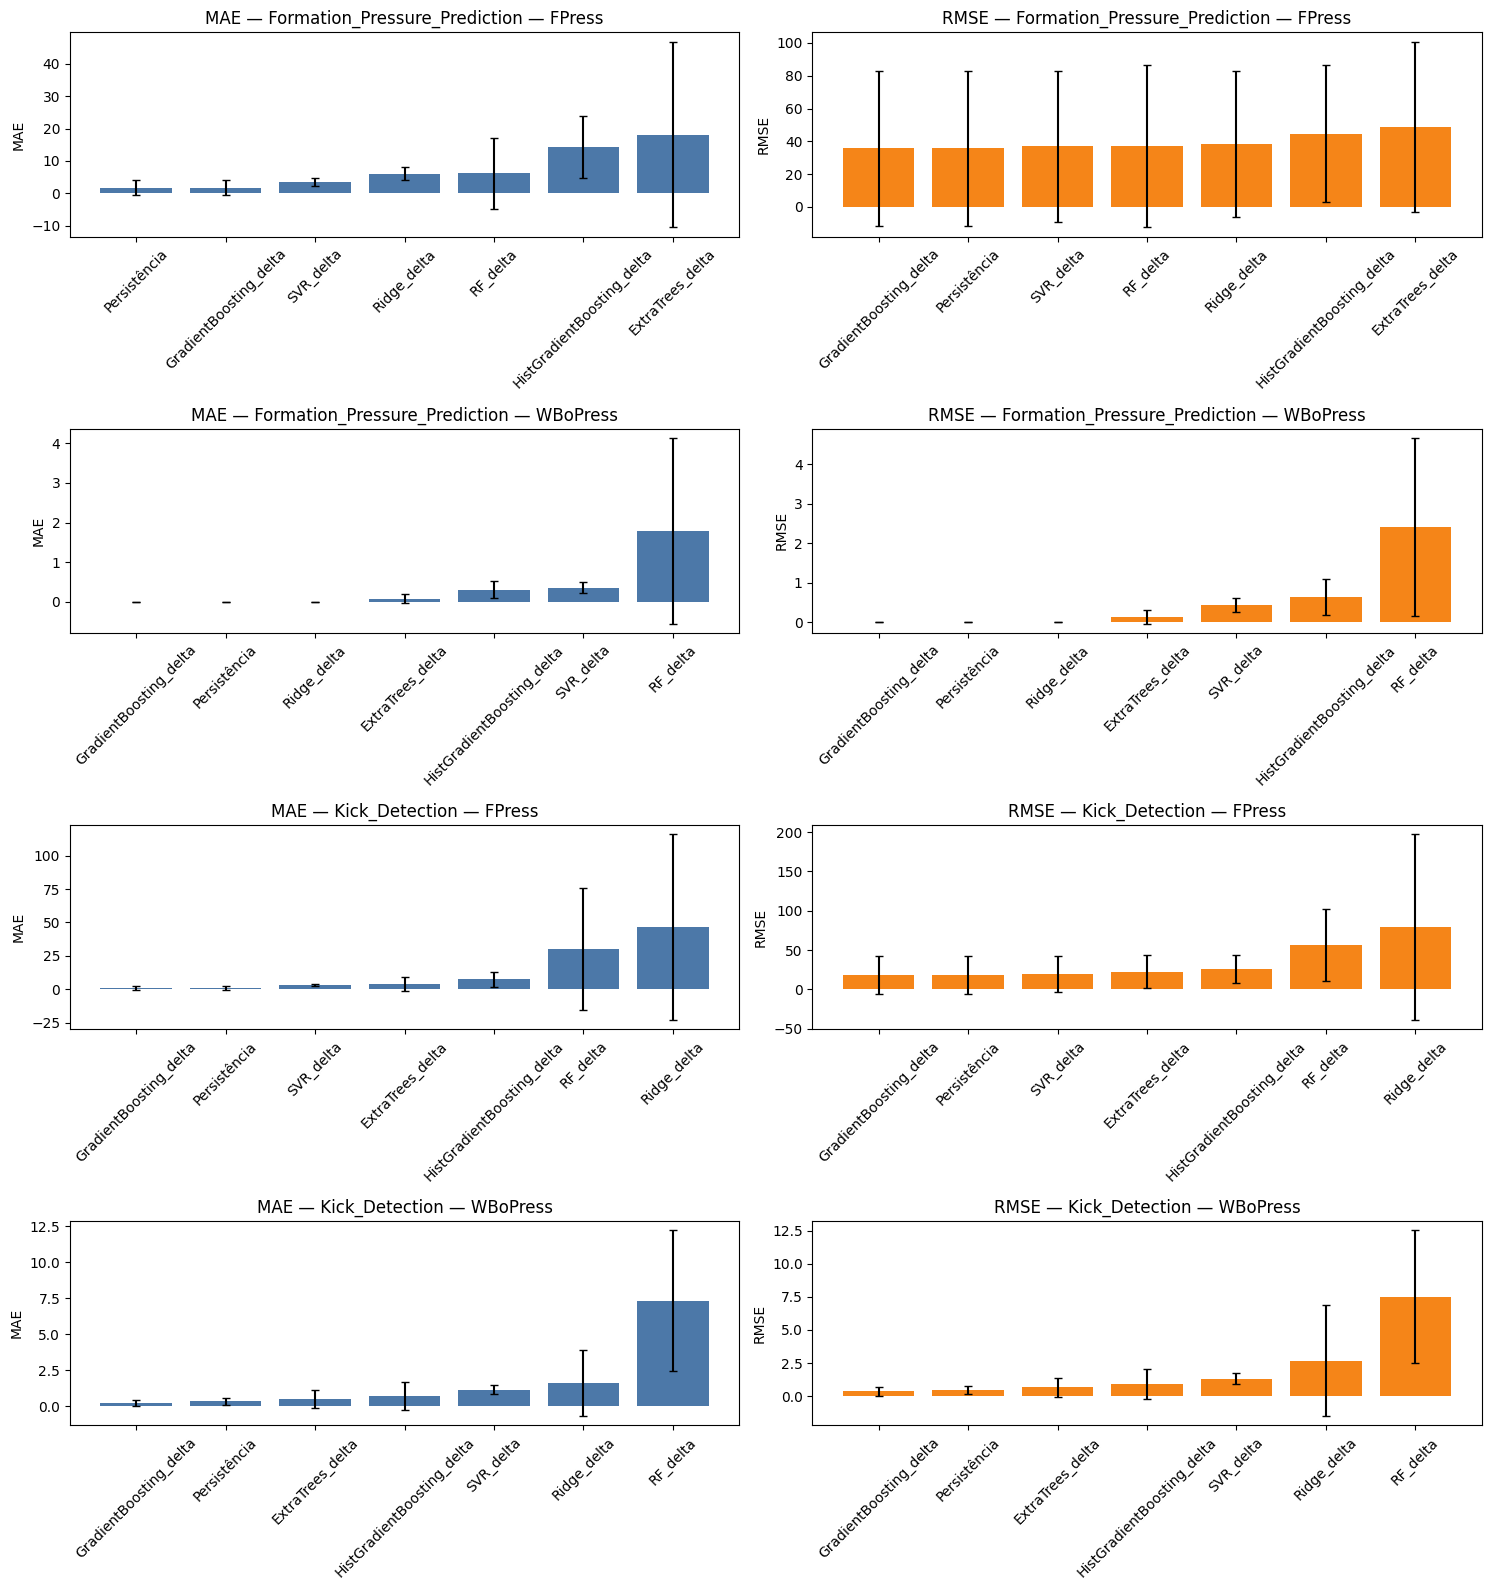

Ganho sobre persistência; positivo indica menor erro:


,dataset,alvo,modelo,ganho_MAE_%,ganho_RMSE_%
0,Formation_Pressure_Prediction,FPress,ExtraTrees_delta,-937.14,-37.13
1,Formation_Pressure_Prediction,FPress,GradientBoosting_delta,-0.01,0.00
2,Formation_Pressure_Prediction,FPress,HistGradientBoosting_delta,-725.47,-25.31
4,Formation_Pressure_Prediction,FPress,RF_delta,-253.64,-3.60
5,Formation_Pressure_Prediction,FPress,Ridge_delta,-246.53,-7.42
6,Formation_Pressure_Prediction,FPress,SVR_delta,-100.54,-3.41
7,Formation_Pressure_Prediction,WBoPress,ExtraTrees_delta,-3377.18,-3949.05
8,Formation_Pressure_Prediction,WBoPress,GradientBoosting_delta,31.78,22.56
9,Formation_Pressure_Prediction,WBoPress,HistGradientBoosting_delta,-12352.87,-20287.63
11,Formation_Pressure_Prediction,WBoPress,RF_delta,-72013.39,-77621.81


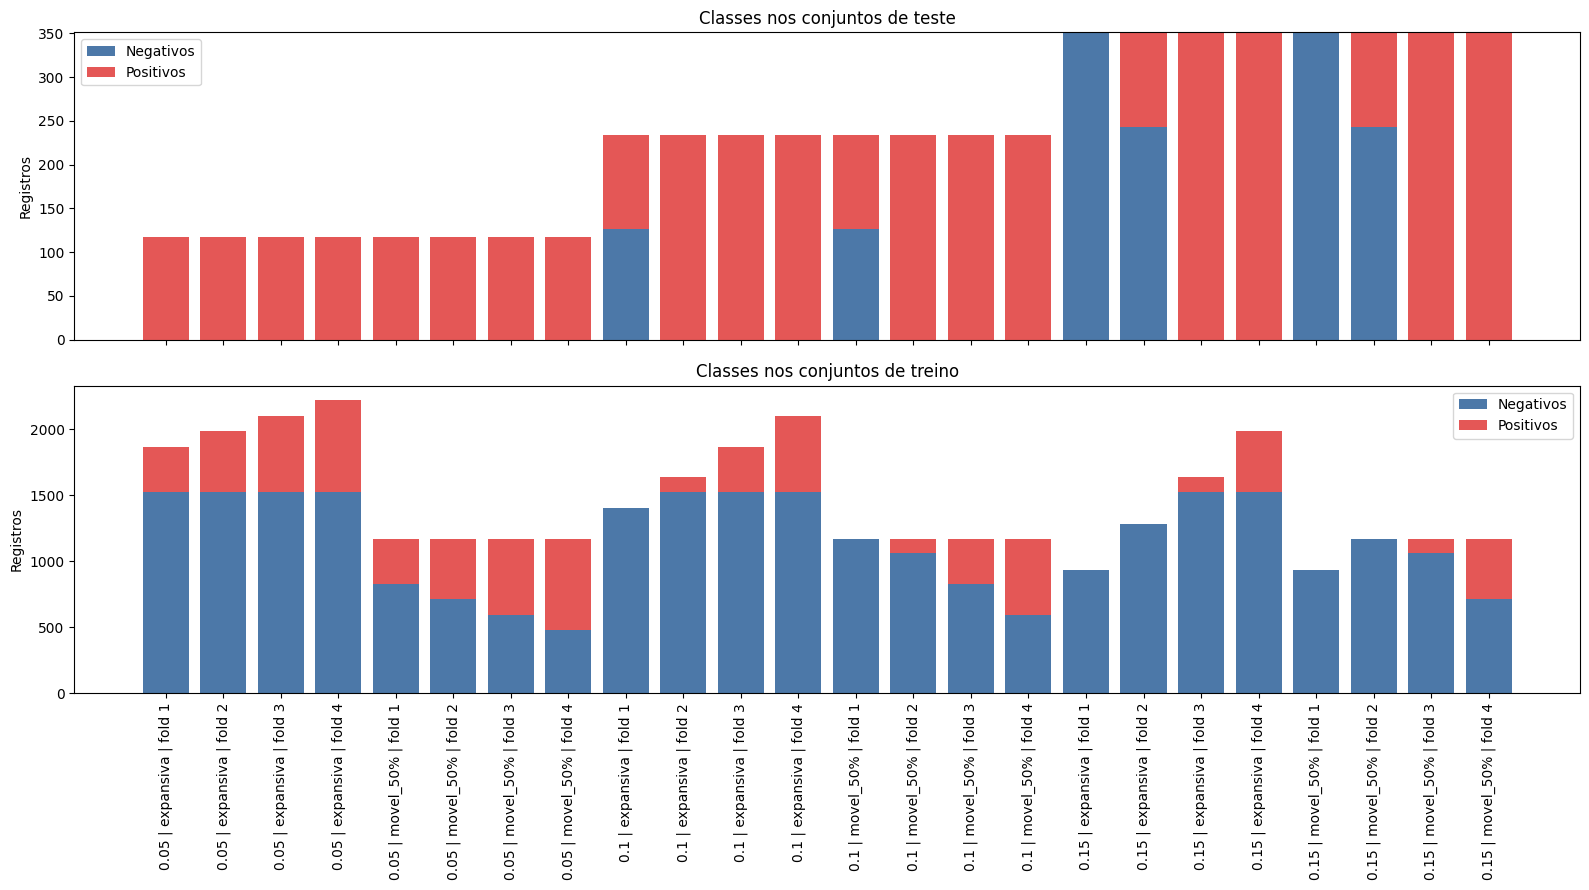

Kick_Detection: colunas constantes removidas: ['CPress', 'MPS1', 'MPS2', 'MPS3', 'AMTD', 'STP']


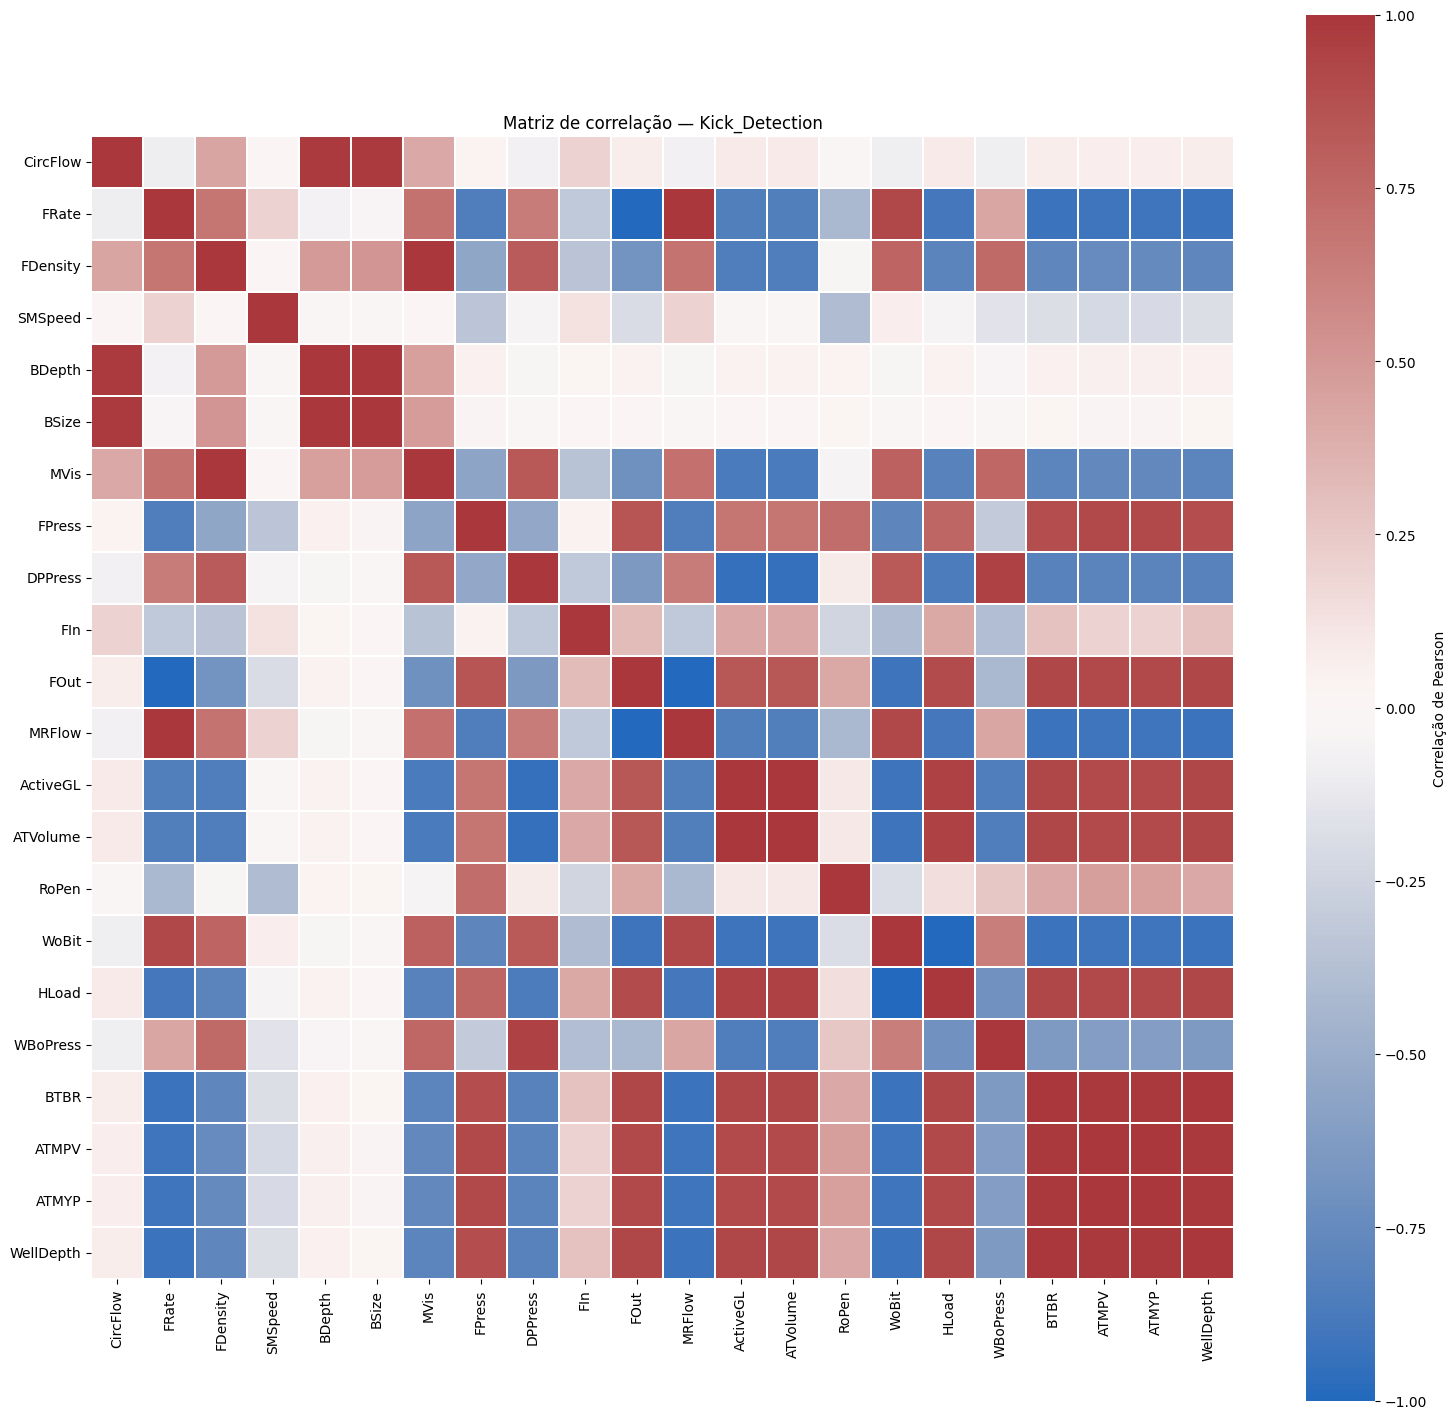

Maiores correlações absolutas — Kick_Detection:


,variavel_1,variavel_2,correlacao
227,BTBR,WellDepth,1.000
186,ActiveGL,ATVolume,1.000
165,FOut,MRFlow,-1.000
29,FRate,FOut,-1.000
30,FRate,MRFlow,1.000
78,BDepth,BSize,1.000
44,FDensity,MVis,0.999
228,ATMPV,ATMYP,0.997
210,WoBit,HLoad,-0.996
230,ATMYP,WellDepth,0.991


Formation_Pressure_Prediction: colunas constantes removidas: ['CPress', 'ActiveGL', 'ATVolume', 'MPS1', 'MPS2', 'MPS3', 'AMTD', 'ATMPV', 'ATMYP', 'STP']


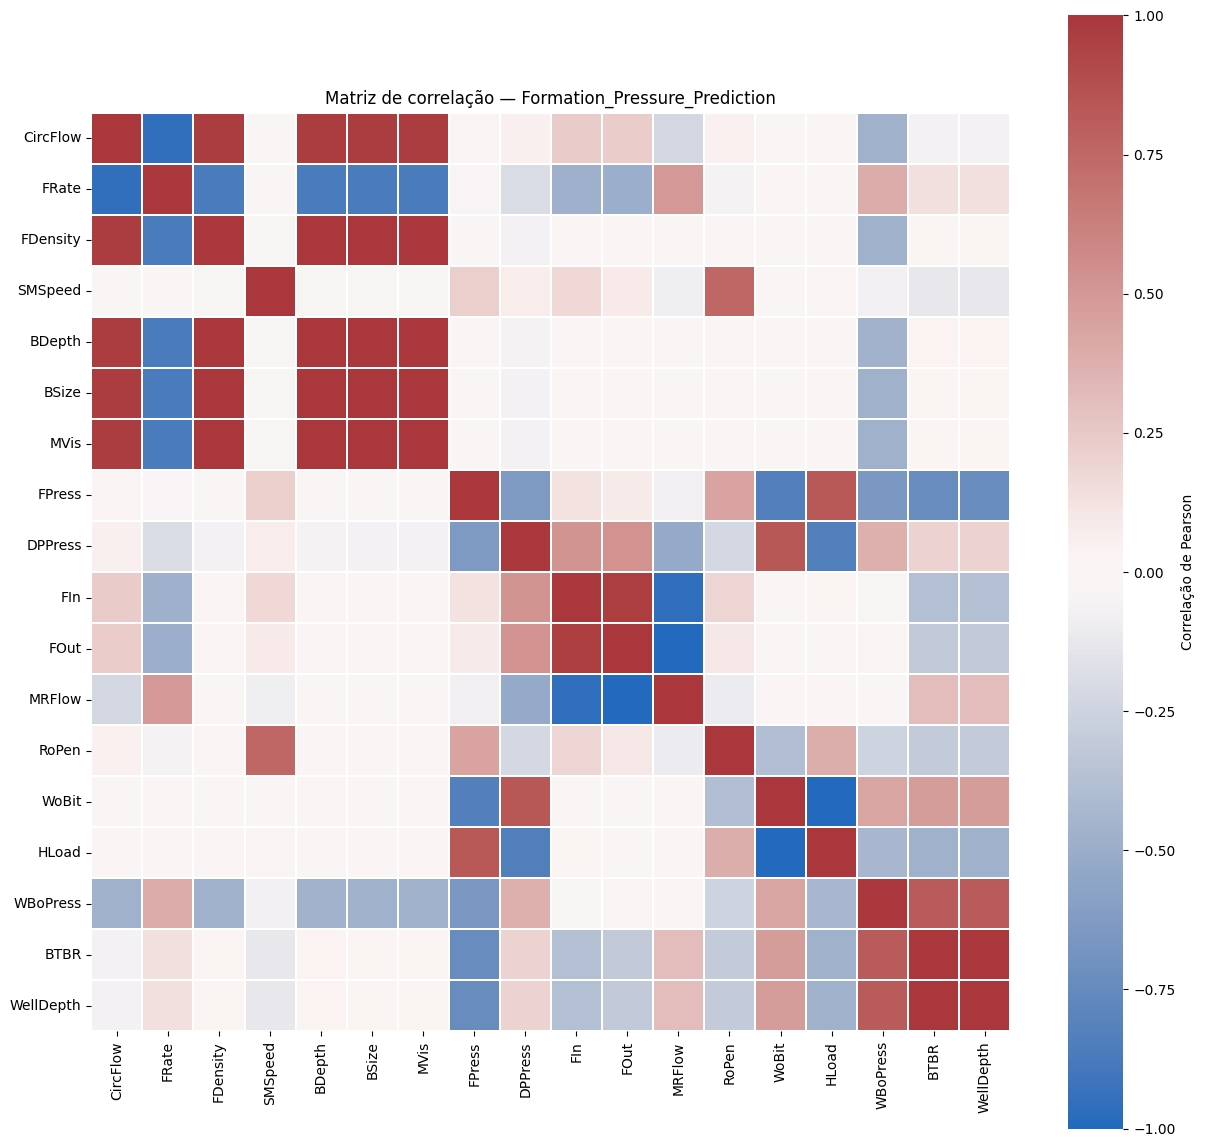

Maiores correlações absolutas — Formation_Pressure_Prediction:


,variavel_1,variavel_2,correlacao
152,BTBR,WellDepth,1.000
35,FDensity,BSize,1.000
36,FDensity,MVis,1.000
75,BSize,MVis,1.000
125,FOut,MRFlow,-1.000
143,WoBit,HLoad,-1.000
62,BDepth,BSize,1.000
63,BDepth,MVis,1.000
34,FDensity,BDepth,1.000
1,CircFlow,FDensity,0.973


Resultados salvos em:
/content/benchmark_regressao_corrigido.csv
/content/diagnostico_kick_corrigido.csv


In [8]:
# ---------- Gráficos de MAE e RMSE ----------
from matplotlib import pyplot as plt
import matplotlib.pyplot as plt
import seaborn as sns


config_principal = reg_benchmark[
    (reg_benchmark["test_fraction"] == 0.15)
    & (reg_benchmark["train_window"] == "expansiva")
]

if not config_principal.empty:
    grupos = list(
        config_principal.groupby(["dataset", "alvo"], dropna=False)
    )

    fig, axes = plt.subplots(
        len(grupos), 2,
        figsize=(15, max(4, 4 * len(grupos))),
        squeeze=False
    )

    for i, ((dataset, alvo), grupo) in enumerate(grupos):
        ordem_mae = (
            grupo.groupby("modelo")["MAE"].mean().sort_values().index
        )
        medias_mae = grupo.groupby("modelo")["MAE"].mean().reindex(ordem_mae)
        std_mae = grupo.groupby("modelo")["MAE"].std().reindex(ordem_mae).fillna(0)

        axes[i, 0].bar(
            medias_mae.index, medias_mae.values,
            yerr=std_mae.values, capsize=3, color="#4C78A8"
        )
        axes[i, 0].set_title(f"MAE — {dataset} — {alvo}")
        axes[i, 0].set_ylabel("MAE")
        axes[i, 0].tick_params(axis="x", rotation=45)

        ordem_rmse = (
            grupo.groupby("modelo")["RMSE"].mean().sort_values().index
        )
        medias_rmse = grupo.groupby("modelo")["RMSE"].mean().reindex(ordem_rmse)
        std_rmse = grupo.groupby("modelo")["RMSE"].std().reindex(ordem_rmse).fillna(0)

        axes[i, 1].bar(
            medias_rmse.index, medias_rmse.values,
            yerr=std_rmse.values, capsize=3, color="#F58518"
        )
        axes[i, 1].set_title(f"RMSE — {dataset} — {alvo}")
        axes[i, 1].set_ylabel("RMSE")
        axes[i, 1].tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()
else:
    print("Não há linhas para a configuração principal escolhida.")

# ---------- Ganho percentual sobre persistência ----------
if not config_principal.empty:
    resumo_principal = (
        config_principal.groupby(
            ["dataset", "alvo", "modelo"], as_index=False
        )[["MAE", "RMSE"]].mean()
    )

    persist = (
        resumo_principal[resumo_principal["modelo"] == "Persistência"]
        [["dataset", "alvo", "MAE", "RMSE"]]
        .rename(columns={
            "MAE": "MAE_persistencia",
            "RMSE": "RMSE_persistencia",
        })
    )

    ganhos = resumo_principal.merge(
        persist, on=["dataset", "alvo"], how="left"
    )
    ganhos = ganhos[ganhos["modelo"] != "Persistência"].copy()

    ganhos["ganho_MAE_%"] = (
        100 * (ganhos["MAE_persistencia"] - ganhos["MAE"])
        / ganhos["MAE_persistencia"]
    )
    ganhos["ganho_RMSE_%"] = (
        100 * (ganhos["RMSE_persistencia"] - ganhos["RMSE"])
        / ganhos["RMSE_persistencia"]
    )

    print("Ganho sobre persistência; positivo indica menor erro:")
    display(
        ganhos[
            ["dataset", "alvo", "modelo", "ganho_MAE_%", "ganho_RMSE_%"]
        ].round(2)
    )

# ---------- Distribuição das classes nos folds ----------
diag_plot = class_diagnostic.drop_duplicates(
    ["test_fraction", "train_window", "fold"]
).copy()

if not diag_plot.empty:
    diag_plot["id_fold"] = (
        diag_plot["test_fraction"].astype(str)
        + " | "
        + diag_plot["train_window"].astype(str)
        + " | fold "
        + diag_plot["fold"].astype(str)
    )

    x = np.arange(len(diag_plot))
    fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

    axes[0].bar(
        x, diag_plot["negativos_teste"],
        label="Negativos", color="#4C78A8"
    )
    axes[0].bar(
        x, diag_plot["positivos_teste"],
        bottom=diag_plot["negativos_teste"],
        label="Positivos", color="#E45756"
    )
    axes[0].set_title("Classes nos conjuntos de teste")
    axes[0].set_ylabel("Registros")
    axes[0].legend()

    axes[1].bar(
        x, diag_plot["negativos_treino"],
        label="Negativos", color="#4C78A8"
    )
    axes[1].bar(
        x, diag_plot["positivos_treino"],
        bottom=diag_plot["negativos_treino"],
        label="Positivos", color="#E45756"
    )
    axes[1].set_title("Classes nos conjuntos de treino")
    axes[1].set_ylabel("Registros")
    axes[1].legend()
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(diag_plot["id_fold"], rotation=90)

    plt.tight_layout()
    plt.show()

# ---------- Matrizes de correlação ----------
def plot_correlacao(df, titulo):
    numericos = df.select_dtypes(include=np.number).copy()
    numericos = numericos.replace([np.inf, -np.inf], np.nan)

    constantes = [
        c for c in numericos.columns
        if numericos[c].nunique(dropna=True) <= 1
    ]
    if constantes:
        print(f"{titulo}: colunas constantes removidas: {constantes}")
        numericos = numericos.drop(columns=constantes)

    if numericos.shape[1] < 2:
        print(f"{titulo}: colunas variáveis insuficientes para correlação.")
        return

    corr = numericos.corr(method="pearson")

    plt.figure(figsize=(
        max(9, 0.7 * len(corr.columns)),
        max(7, 0.65 * len(corr.columns))
    ))
    sns.heatmap(
        corr,
        cmap="vlag",
        vmin=-1,
        vmax=1,
        center=0,
        annot=len(corr.columns) <= 14,
        fmt=".2f",
        square=True,
        linewidths=0.3,
        cbar_kws={"label": "Correlação de Pearson"}
    )
    plt.title(f"Matriz de correlação — {titulo}")
    plt.tight_layout()
    plt.show()

    pares = (
        corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .reset_index()
    )
    if len(pares):
        pares.columns = ["variavel_1", "variavel_2", "correlacao"]
        pares["abs_correlacao"] = pares["correlacao"].abs()
        print(f"Maiores correlações absolutas — {titulo}:")
        display(
            pares.sort_values("abs_correlacao", ascending=False)
            .head(10)[["variavel_1", "variavel_2", "correlacao"]]
            .round(3)
        )

plot_correlacao(kick_df, "Kick_Detection")
plot_correlacao(pressure_df, "Formation_Pressure_Prediction")

# ---------- Salvar tabelas completas ----------
reg_benchmark.to_csv(
    "/content/benchmark_regressao_corrigido.csv", index=False
)
class_diagnostic.to_csv(
    "/content/diagnostico_kick_corrigido.csv", index=False
)

print("Resultados salvos em:")
print("/content/benchmark_regressao_corrigido.csv")
print("/content/diagnostico_kick_corrigido.csv")